<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-1-Basic-Neuron/activation_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

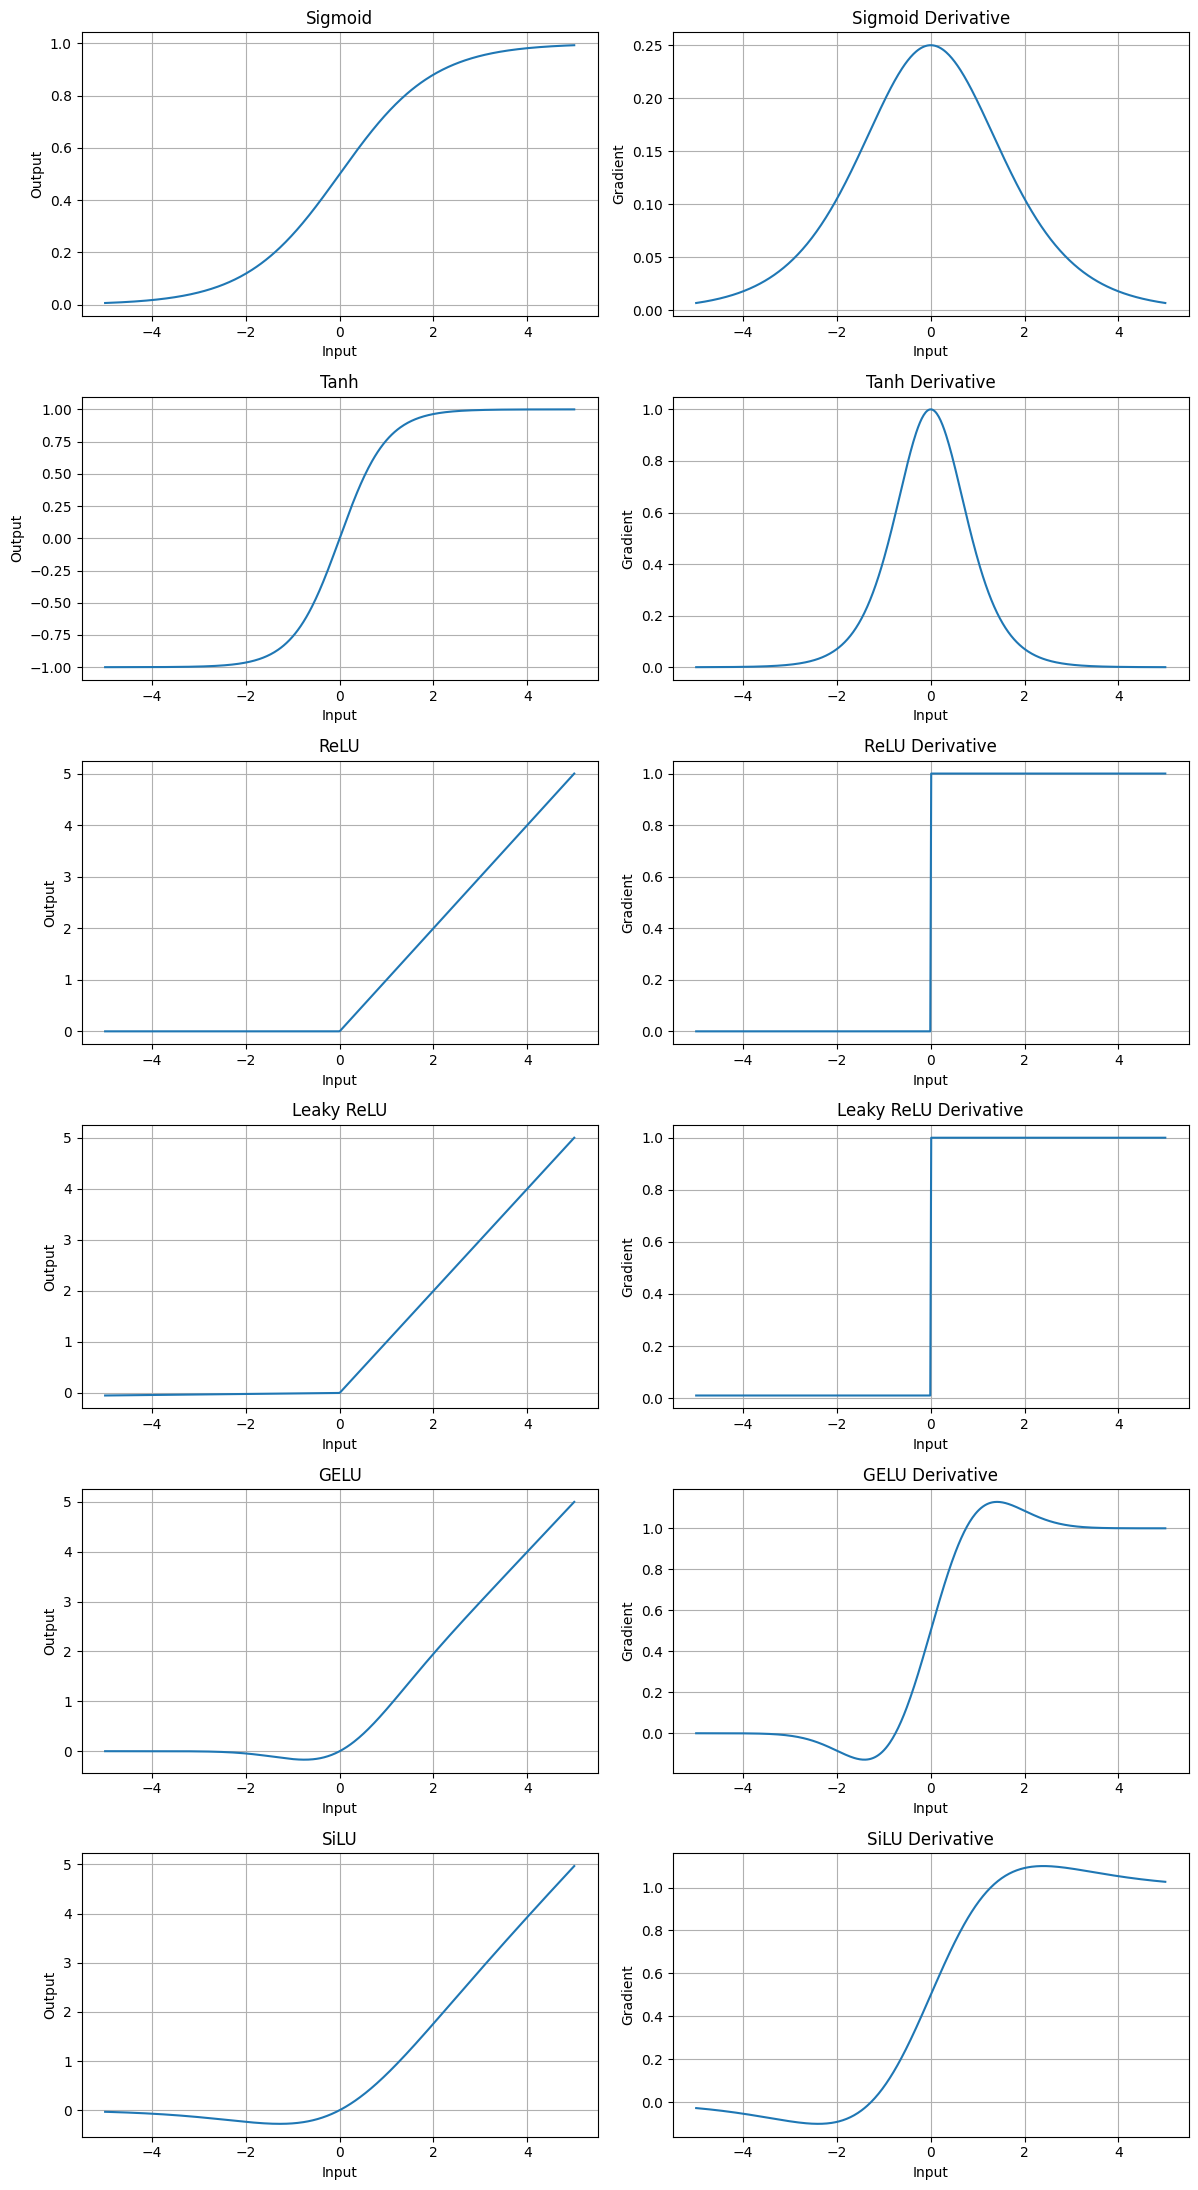

GRADIENT FLOW ANALYSIS
---------------------------------------------

Activation: Sigmoid
Mean absolute gradient: 0.0985
Maximum absolute gradient: 0.25

Activation: Tanh
Mean absolute gradient: 0.1996
Maximum absolute gradient: 0.9999

Activation: ReLU
Mean absolute gradient: 0.5
Maximum absolute gradient: 1

Activation: Leaky ReLU
Mean absolute gradient: 0.505
Maximum absolute gradient: 1.0

Activation: GELU
Mean absolute gradient: 0.5339
Maximum absolute gradient: 1.1289

Activation: SiLU
Mean absolute gradient: 0.549
Maximum absolute gradient: 1.0998


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

# Define input range
x = np.linspace(-5, 5, 500)

# 1. Sigmoid
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

# 2. Tanh
def tanh(x):
    return np.tanh(x)

def tanh_derivative(x):
    return 1 - np.tanh(x)**2

# 3. ReLU
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)

# 4. Leaky ReLU
def leaky_relu(x):
    return np.where(x > 0, x, 0.01 * x)

def leaky_relu_derivative(x):
    return np.where(x > 0, 1, 0.01)

# 5. GELU
def gelu(x):
    return 0.5 * x * (1 + erf(x / np.sqrt(2)))

def gelu_derivative(x):
    pdf = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
    cdf = 0.5 * (1 + erf(x / np.sqrt(2)))
    return cdf + x * pdf

# 6. SiLU
def silu(x):
    return x * sigmoid(x)

def silu_derivative(x):
    s = sigmoid(x)
    return s + x * s * (1 - s)


# Store activation functions
activations = {
    "Sigmoid": (sigmoid, sigmoid_derivative),
    "Tanh": (tanh, tanh_derivative),
    "ReLU": (relu, relu_derivative),
    "Leaky ReLU": (leaky_relu, leaky_relu_derivative),
    "GELU": (gelu, gelu_derivative),
    "SiLU": (silu, silu_derivative)
}

# Plot activation functions and derivatives
fig, axes = plt.subplots(6, 2, figsize=(12, 22))

for i, (name, (func, derivative)) in enumerate(activations.items()):

    axes[i, 0].plot(x, func(x))
    axes[i, 0].set_title(name)
    axes[i, 0].set_xlabel("Input")
    axes[i, 0].set_ylabel("Output")
    axes[i, 0].grid(True)

    axes[i, 1].plot(x, derivative(x))
    axes[i, 1].set_title(name + " Derivative")
    axes[i, 1].set_xlabel("Input")
    axes[i, 1].set_ylabel("Gradient")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()


# Investigate gradient flow
print("GRADIENT FLOW ANALYSIS")
print("-" * 45)

for name, (func, derivative) in activations.items():

    gradients = derivative(x)

    mean_gradient = np.mean(np.abs(gradients))
    max_gradient = np.max(np.abs(gradients))

    print("\nActivation:", name)
    print("Mean absolute gradient:", round(mean_gradient, 4))
    print("Maximum absolute gradient:", round(max_gradient, 4))

##Observations and Conclusion

1. Sigmoid: Produces outputs between 0 and 1 but can suffer from vanishing gradients.
2. Tanh: Produces outputs between -1 and 1 and is zero-centered.
3. ReLU: Helps reduce vanishing gradients for positive inputs but has zero gradients for negative inputs.
4. Leaky ReLU: Allows a small gradient for negative inputs.
5. GELU: Provides a smooth activation and is commonly used in modern neural network architectures.
6. SiLU: A smooth activation function that can improve gradient flow.

Conclusion

Different activation functions influence gradient flow and neural network learning. Choosing a suitable activation function can improve training performance and convergence.